# Lab 1 – PCA · Dataset 2: Wine Quality (UCI ID 186)

Files: `winequality-red.csv`, `winequality-white.csv`. Separator is `;`.

In [319]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

## I. Study the dataset
Each file is loaded separately. Cleaning is done per file.

In [320]:
DATA_DIR = "data"
red = pd.read_csv(f"{DATA_DIR}/winequality-red.csv", sep=";")
white = pd.read_csv(f"{DATA_DIR}/winequality-white.csv", sep=";")

datasets = {"red": red, "white": white}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

# Sanity check: 11 features + quality = 12 columns.
assert red.shape[1] == 12 and white.shape[1] == 12, "Wrong separator? Use sep=';'"
assert list(red.columns) == list(white.columns), "Column names differ between files"

red: 1599 rows, 12 columns
white: 4898 rows, 12 columns


In [321]:
red.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [322]:
# Column types: all should be numeric (float64, quality int64)
pd.DataFrame({"red": red.dtypes, "white": white.dtypes})

,red,white
fixed acidity,float64,float64
volatile acidity,float64,float64
citric acid,float64,float64
residual sugar,float64,float64
chlorides,float64,float64
free sulfur dioxide,float64,float64
total sulfur dioxide,float64,float64
density,float64,float64
pH,float64,float64
sulphates,float64,float64


### 1. Feature types

In [323]:
both = pd.concat([red, white])
feature_info = pd.DataFrame({
    "dtype": both.dtypes.astype(str),
    "n_unique": both.nunique(),
    "min": both.min(),
    "max": both.max(),
    "all_whole_numbers": (both % 1 == 0).all(),
})
feature_info

,dtype,n_unique,min,max,all_whole_numbers
fixed acidity,float64,106,3.80000,15.90000,False
volatile acidity,float64,187,0.08000,1.58000,False
citric acid,float64,89,0.00000,1.66000,False
residual sugar,float64,316,0.60000,65.80000,False
chlorides,float64,214,0.00900,0.61100,False
free sulfur dioxide,float64,135,1.00000,289.00000,False
total sulfur dioxide,float64,276,6.00000,440.00000,False
density,float64,998,0.98711,1.03898,False
pH,float64,108,2.72000,4.01000,False
sulphates,float64,111,0.22000,2.00000,False


Classification (based on the UCI dataset page and Cortez et al. 2009):

| Feature | Quantitative / Qualitative | Numerical / Categorical | Discrete / Continuous |
|---|---|---|---|
| `fixed acidity`, `volatile acidity`, `citric acid`, `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide`, `density`, `pH`, `sulphates`, `alcohol` | Quantitative | Numerical | Continuous |
| `quality` (label, score 0–10) | Qualitative (ordinal) | Categorical | Discrete |
| `type` (added at integration: red / white) | Qualitative (nominal) | Categorical | Discrete |

Note: `quality` is the median of expert grades on an ordered scale: the order matters, but the distance between two grades is not a measured quantity.

### 2. Missing values

In [324]:
missing = pd.DataFrame({
    "red_missing": red.isna().sum(),
    "white_missing": white.isna().sum(),
})
print("Rows with at least one missing value:")
for name, df in datasets.items():
    print(f"  {name}: {df.isna().any(axis=1).sum()}")
missing

Rows with at least one missing value:
  red: 0
  white: 0


,red_missing,white_missing
fixed acidity,0,0
volatile acidity,0,0
citric acid,0,0
residual sugar,0,0
chlorides,0,0
free sulfur dioxide,0,0
total sulfur dioxide,0,0
density,0,0
pH,0,0
sulphates,0,0


### 3. Duplicate records

In [325]:
for name, df in datasets.items():
    n_dup = df.duplicated().sum()
    print(f"{name}: {n_dup} duplicate rows ({n_dup / len(df) * 100:.2f}%)")

red: 240 duplicate rows (15.01%)
white: 937 duplicate rows (19.13%)


In [326]:
# Look at some duplicated groups (keep=False shows all copies)
red[red.duplicated(keep=False)].sort_values(list(red.columns)).head(6)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
142,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6
144,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6
131,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5
132,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5
1488,5.6,0.54,0.04,1.7,0.049,5.0,13.0,0.9942,3.72,0.58,11.4,5
1491,5.6,0.54,0.04,1.7,0.049,5.0,13.0,0.9942,3.72,0.58,11.4,5


### 4. Inconsistency
Rows with the same 11 features but a different `quality`

In [327]:
features = [c for c in red.columns if c != "quality"]

for name, df in datasets.items():
    same_features = df.duplicated(subset=features, keep=False)
    groups = df[same_features].groupby(features)["quality"].nunique()
    n_conflict = (groups > 1).sum()
    print(f"{name}: {(groups > 0).sum()} duplicate feature groups, "
          f"{n_conflict} with different quality")

red: 220 duplicate feature groups, 0 with different quality
white: 772 duplicate feature groups, 0 with different quality


### Drop duplicates

In [328]:
red_clean = red.drop_duplicates().reset_index(drop=True)
white_clean = white.drop_duplicates().reset_index(drop=True)
datasets_clean = {"red": red_clean, "white": white_clean}

for name in datasets:
    before, after = len(datasets[name]), len(datasets_clean[name])
    print(f"{name}: {before} -> {after} rows ({before - after} removed, "
          f"{(before - after) / before * 100:.2f}%)")

red: 1599 -> 1359 rows (240 removed, 15.01%)
white: 4898 -> 3961 rows (937 removed, 19.13%)


### 5. Incorrect values

In [329]:
# Incorrect values (checked on duplicate-free data)
features = [c for c in red_clean.columns if c != 'quality']

def check_incorrect(df, name):
    rules = {
        'Negative value (any feature)': (df[features] < 0).any(axis=1),
        'pH outside 0-14': ~df['pH'].between(0, 14),
        'Alcohol outside 0-100 % vol': ~df['alcohol'].between(0, 100),
        'Density <= 0': df['density'] <= 0,
        'Free SO2 > total SO2': df['free sulfur dioxide'] > df['total sulfur dioxide'],
        'Quality not an integer 0-10': ~df['quality'].between(0, 10) | (df['quality'] % 1 != 0),
    }
    result = pd.DataFrame({'Rows flagged': {k: int(v.sum()) for k, v in rules.items()}})
    result['Percentage (%)'] = (result['Rows flagged'] / len(df) * 100).round(2)
    any_flag = pd.concat(rules.values(), axis=1).any(axis=1)
    print(f'{name}: {int(any_flag.sum())} of {len(df)} rows have at least one incorrect value')
    return result, any_flag

res_red, bad_red = check_incorrect(red_clean, 'Red')
res_white, bad_white = check_incorrect(white_clean, 'White')
display(pd.concat({'Red': res_red, 'White': res_white}, axis=1))

Red: 0 of 1359 rows have at least one incorrect value
White: 0 of 3961 rows have at least one incorrect value


Red                       White  \
                             Rows flagged Percentage (%) Rows flagged   
Negative value (any feature)            0            0.0            0   
pH outside 0-14                         0            0.0            0   
Alcohol outside 0-100 % vol             0            0.0            0   
Density <= 0                            0            0.0            0   
Free SO2 > total SO2                    0            0.0            0   
Quality not an integer 0-10             0            0.0            0   

                                             
                             Percentage (%)  
Negative value (any feature)            0.0  
pH outside 0-14                         0.0  
Alcohol outside 0-100 % vol             0.0  
Density <= 0                            0.0  
Free SO2 > total SO2                    0.0  
Quality not an integer 0-10             0.0

In [330]:
display(pd.concat({'Red': red_clean[features].agg(['min', 'max']).T,
                   'White': white_clean[features].agg(['min', 'max']).T}, axis=1))

Red               White           
                          min        max      min        max
fixed acidity         4.60000   15.90000  3.80000   14.20000
volatile acidity      0.12000    1.58000  0.08000    1.10000
citric acid           0.00000    1.00000  0.00000    1.66000
residual sugar        0.90000   15.50000  0.60000   65.80000
chlorides             0.01200    0.61100  0.00900    0.34600
free sulfur dioxide   1.00000   72.00000  2.00000  289.00000
total sulfur dioxide  6.00000  289.00000  9.00000  440.00000
density               0.99007    1.00369  0.98711    1.03898
pH                    2.74000    4.01000  2.72000    3.82000
sulphates             0.33000    2.00000  0.22000    1.08000
alcohol               8.40000   14.90000  8.00000   14.20000

### 6. Outliers (IQR)

In [331]:
# Outliers (IQR, 1.5 x IQR), on duplicate-free data
def iqr_outliers(df, name):
    X = df[features]
    q1, q3 = X.quantile(0.25), X.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flags = (X < lower) | (X > upper)
    table = pd.DataFrame({
        'Lower bound': lower.round(4),
        'Upper bound': upper.round(4),
        'Flagged outliers': flags.sum(),
        'Percentage (%)': (flags.sum() / len(df) * 100).round(2),
    })
    any_out = flags.any(axis=1)
    print(f'{name}: {int(any_out.sum())} of {len(df)} rows '
          f'({any_out.mean() * 100:.2f}%) have at least one outlier')
    return table

out_red = iqr_outliers(red_clean, 'Red')
out_white = iqr_outliers(white_clean, 'White')
display(pd.concat({'Red': out_red, 'White': out_white}, axis=1))

Red: 340 of 1359 rows (25.02%) have at least one outlier
White: 706 of 3961 rows (17.82%) have at least one outlier


Red                                              \
                     Lower bound Upper bound Flagged outliers Percentage (%)   
fixed acidity             3.9500     12.3500               41           3.02   
volatile acidity          0.0150      1.0150               19           1.40   
citric acid              -0.4200      0.9400                1           0.07   
residual sugar            0.8500      3.6500              126           9.27   
chlorides                 0.0385      0.1225               87           6.40   
free sulfur dioxide     -14.0000     42.0000               26           1.91   
total sulfur dioxide    -39.5000    124.5000               45           3.31   
density                   0.9923      1.0012               35           2.58   
pH                        2.9250      3.6850               28           2.06   
sulphates                 0.2800      1.0000               55           4.05   
alcohol                   7.1000     13.5000               12           0.88   

                           White                                              
                     Lower bound Upper bound Flagged outliers Percentage (%)  
fixed acidity             4.8000      8.8000              106           2.68  
volatile acidity          0.0300      0.5100              133           3.36  
citric acid               0.0900      0.5700              223           5.63  
residual sugar           -9.3500     19.8500               16           0.40  
chlorides                 0.0125      0.0725              178           4.49  
free sulfur dioxide     -10.0000     78.0000               44           1.11  
total sulfur dioxide     16.0000    256.0000               14           0.35  
density                   0.9855      1.0018                6           0.15  
pH                        2.7900      3.5900               46           1.16  
sulphates                 0.2000      0.7600               96           2.42  
alcohol                   6.6500     14.2500                0           0.00

## Cleaning summary (before/after)

In [332]:
# --- Cleaning summary: before (raw) vs after (clean), per file ---
red_raw, white_raw = red, white

def n_inconsistent(df):
    n_q = df.groupby(features)['quality'].transform('nunique')
    return int((n_q > 1).sum())

def n_out_rows(df):
    X = df[features]
    q1, q3 = X.quantile(0.25), X.quantile(0.75)
    iqr = q3 - q1
    return int(((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).any(axis=1).sum())

def summary(raw, clean, bad_clean):
    return pd.DataFrame({
        'Before': [len(raw), int(raw.isna().any(axis=1).sum()), int(raw.duplicated().sum()),
                   n_inconsistent(raw), int(bad_clean.sum()), '-'],
        'After':  [len(clean), int(clean.isna().any(axis=1).sum()), int(clean.duplicated().sum()),
                   n_inconsistent(clean), int(bad_clean.sum()), f'{n_out_rows(clean)} (kept)'],
    }, index=['Total records', 'Records with missing values', 'Duplicate records',
              'Records with detected inconsistencies', 'Records with incorrect values',
              'Records with at least one IQR outlier'])

tab = pd.concat({'Red': summary(red_raw, red_clean, bad_red),
                 'White': summary(white_raw, white_clean, bad_white)}, axis=1)
display(tab)

for name, raw in [('Red', red_raw), ('White', white_raw)]:
    print(f'{name}: {raw.duplicated().sum() / len(raw) * 100:.2f}% duplicates')
    
print('\nRemoved records - Red:', len(red_raw) - len(red_clean),
      '| White:', len(white_raw) - len(white_clean))

Red              White            
                                      Before       After Before       After
Total records                           1599        1359   4898        3961
Records with missing values                0           0      0           0
Duplicate records                        240           0    937           0
Records with detected inconsistencies      0           0      0           0
Records with incorrect values              0           0      0           0
Records with at least one IQR outlier      -  340 (kept)      -  706 (kept)

Red: 15.01% duplicates
White: 19.13% duplicates

Removed records - Red: 240 | White: 937


## II. Data integration

In [333]:
# Schema check: both files must have the same columns, in the same order
print("Same columns:", list(red_clean.columns) == list(white_clean.columns))

features = list(red_clean.columns.drop('quality'))   # the 11 physicochemical features

# Add the type column and stack the two files (vertical merge, not a join)
wine = pd.concat(
    [red_clean.assign(type='red'), white_clean.assign(type='white')],
    ignore_index=True
)
print(wine.shape)
wine.head()

Same columns: True
(5320, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,red


In [334]:
# Rows that appear in both files (same 11 features + quality)
common = red_clean.merge(white_clean, on=list(red_clean.columns), how='inner')

integ_tab = pd.DataFrame({
    'Result': [
        len(red_clean),
        len(white_clean),
        len(wine),
        len(wine) == len(red_clean) + len(white_clean),
        int(wine.isna().sum().sum()),
        len(common),
    ]
}, index=[
    'Rows red (after cleaning)',
    'Rows white (after cleaning)',
    'Rows after integration',
    'No rows lost or duplicated',
    'Missing values after integration',
    'Identical rows found in both files',
])
integ_tab

,Result
Rows red (after cleaning),1359
Rows white (after cleaning),3961
Rows after integration,5320
No rows lost or duplicated,True
Missing values after integration,0
Identical rows found in both files,2


In [335]:
type_tab = wine['type'].value_counts().to_frame('Count')
type_tab['Percentage (%)'] = (type_tab['Count'] / len(wine) * 100).round(2)
type_tab

,Count,Percentage (%)
type,,
white,3961,74.45
red,1359,25.55


In [336]:
wine.groupby('type')[features].mean().T.round(3)

type,red,white
fixed acidity,8.311,6.839
volatile acidity,0.529,0.281
citric acid,0.272,0.334
residual sugar,2.523,5.915
chlorides,0.088,0.046
free sulfur dioxide,15.893,34.889
total sulfur dioxide,46.826,137.194
density,0.997,0.994
pH,3.310,3.195
sulphates,0.659,0.490


### Data transformation

Z-score standardization (on the merged data)

In [337]:
X = wine[features]                                   # 11 features only, not quality or type
X_std = (X - X.mean()) / X.std(ddof=0)               # z = (x - mean) / std

std_tab = pd.DataFrame({
    'Mean Before': X.mean(),
    'Std Before':  X.std(ddof=0),
    'Mean After':  X_std.mean(),
    'Std After':   X_std.std(ddof=0),
}).round(4)
std_tab

,Mean Before,Std Before,Mean After,Std After
fixed acidity,7.2152,1.3195,0.0,1.0
volatile acidity,0.3441,0.1682,-0.0,1.0
citric acid,0.3185,0.1471,0.0,1.0
residual sugar,5.0485,4.4998,0.0,1.0
chlorides,0.0567,0.0369,0.0,1.0
free sulfur dioxide,30.0367,17.8034,0.0,1.0
total sulfur dioxide,114.1090,56.7689,-0.0,1.0
density,0.9945,0.0030,0.0,1.0
pH,3.2247,0.1604,0.0,1.0
sulphates,0.5334,0.1497,-0.0,1.0


encode `type`

In [338]:
wine['type_code'] = wine['type'].map({'red': 0, 'white': 1})
pd.crosstab(wine['type'], wine['type_code'])

type_code,0,1
type,,
red,1359,0
white,0,3961


final table

In [339]:
wine_std = X_std.copy()
wine_std['quality'] = wine['quality'].values        # label, not scaled
wine_std['type'] = wine['type'].values              # only for colouring plots
wine_std.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,0.140064,2.115349,-2.164515,-0.699699,0.523880,-1.069272,-1.411143,1.100996,1.779304,0.177941,-0.969152,5,red
1,0.443199,3.185297,-2.164515,-0.544135,1.120736,-0.282905,-0.829839,0.763753,-0.153797,0.979389,-0.631833,5,red
2,0.443199,2.471998,-1.892672,-0.610806,0.957957,-0.844596,-1.058837,0.831202,0.220351,0.779027,-0.631833,5,red
3,3.019841,-0.381197,1.641293,-0.699699,0.496751,-0.732258,-0.953146,1.168444,-0.403229,0.311515,-0.631833,6,red
4,0.140064,1.877583,-2.164515,-0.721923,0.496751,-0.956934,-1.305451,1.100996,1.779304,0.177941,-0.969152,5,red


## III. Label and statistics

In [340]:
# Mean and variance (original merged data, ddof=1)
stat_tab = pd.DataFrame({'Mean': X.mean(), 'Variance': X.var(ddof=1)})
stat_tab.style.format({'Mean': '{:.4f}', 'Variance': '{:.4e}'})

,Mean,Variance
fixed acidity,7.2152,1.7415e+00
volatile acidity,0.3441,2.8307e-02
citric acid,0.3185,2.1655e-02
residual sugar,5.0485,2.0252e+01
chlorides,0.0567,1.3589e-03
free sulfur dioxide,30.0367,3.1702e+02
total sulfur dioxide,114.1090,3.2233e+03
density,0.9945,8.7942e-06
pH,3.2247,2.5721e-02
sulphates,0.5334,2.2423e-02


In [341]:
# Covariance matrix
cov_mat = X.cov()          # ddof=1 by default
cov_mat.round(4)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
fixed acidity,1.7415,0.0477,0.0641,-0.6202,0.0141,-6.6165,-24.5352,0.0019,-0.0574,0.0602,-0.1605
volatile acidity,0.0477,0.0283,-0.0095,-0.1239,0.0023,-1.0456,-3.8277,0.0002,0.0067,0.0057,-0.0131
citric acid,0.0641,-0.0095,0.0217,0.0968,0.0003,0.3428,1.6278,0.0000,-0.0081,0.0013,-0.0010
residual sugar,-0.6202,-0.1239,0.0968,20.2516,-0.0204,31.9476,124.5583,0.0070,-0.1693,-0.1177,-1.6290
chlorides,0.0141,0.0023,0.0003,-0.0204,0.0014,-0.1225,-0.5647,0.0000,0.0002,0.0022,-0.0118
free sulfur dioxide,-6.6165,-1.0456,0.3428,31.9476,-0.1225,317.0196,728.3184,0.0003,-0.4048,-0.5286,-3.5899
total sulfur dioxide,-24.5352,-3.8277,1.6278,124.5583,-0.5647,728.3184,3223.3124,0.0011,-2.0301,-2.3450,-16.7655
density,0.0019,0.0002,0.0000,0.0070,0.0000,0.0003,0.0011,0.0000,0.0000,0.0001,-0.0023
pH,-0.0574,0.0067,-0.0081,-0.1693,0.0002,-0.4048,-2.0301,0.0000,0.0257,0.0040,0.0185
sulphates,0.0602,0.0057,0.0013,-0.1177,0.0022,-0.5286,-2.3450,0.0001,0.0040,0.0224,-0.0031


In [342]:
q_tab = wine['quality'].value_counts().sort_index().to_frame('Frequency')
q_tab['Percentage (%)'] = (q_tab['Frequency'] / len(wine) * 100).round(2)
print('Mode:', wine['quality'].mode()[0], '| Median:', wine['quality'].median())
q_tab

Mode: 6 | Median: 6.0


,Frequency,Percentage (%)
quality,,
3,30,0.56
4,206,3.87
5,1752,32.93
6,2323,43.67
7,856,16.09
8,148,2.78
9,5,0.09


In [343]:
# Quality by type (% inside each type)
pd.crosstab(wine['quality'], wine['type'], normalize='columns').mul(100).round(2)

type,red,white
quality,,
3,0.74,0.50
4,3.90,3.86
5,42.46,29.66
6,39.37,45.14
7,12.29,17.39
8,1.25,3.31
9,0.00,0.13


## IV. Correlation analysis

### Correlation matrix (Pearson)

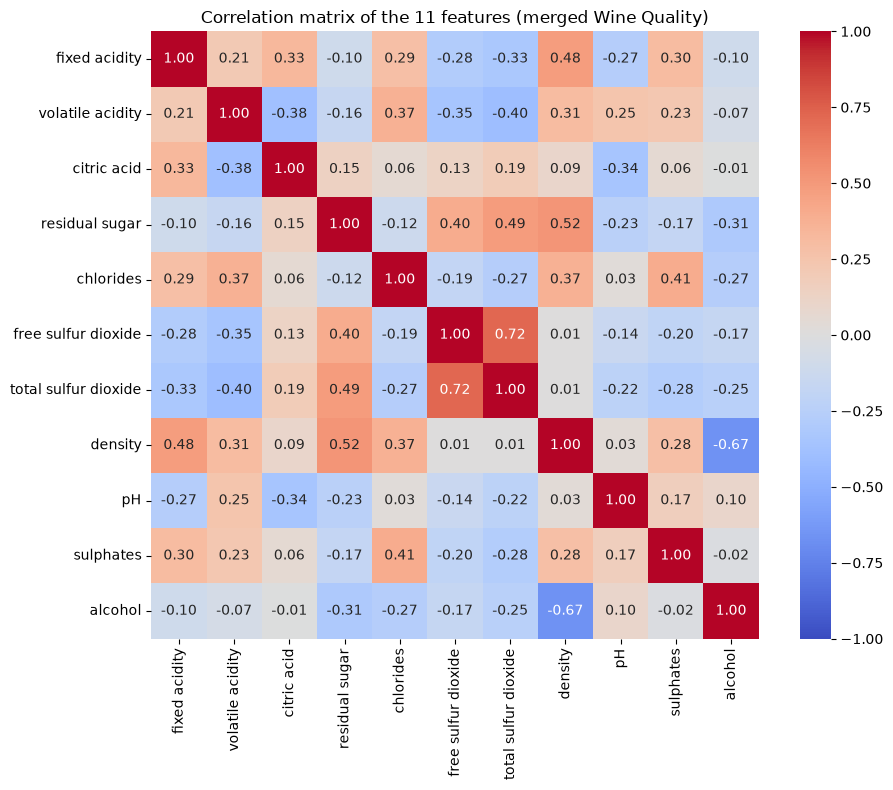

In [344]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = X.corr()   # Pearson
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation matrix of the 11 features (merged Wine Quality)')
plt.tight_layout()
plt.savefig('figures/wine_heatmap.png', dpi=200)
plt.show()

### Strongest pairs (merged data)

In [345]:
def top_pairs(df, n=5):
    c = df[features].corr()
    p = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack()
    return p.reindex(p.abs().sort_values(ascending=False).index).head(n).round(4)

top_pairs(wine).to_frame('r')

r
free sulfur dioxide total sulfur dioxide  0.7205
density             alcohol              -0.6678
residual sugar      density               0.5209
                    total sulfur dioxide  0.4875
fixed acidity       density               0.4782

### Strongest pairs per type (merged vs red vs white)

In [346]:
pd.concat({
    'merged': top_pairs(wine, 3),
    'red':    top_pairs(wine[wine['type'] == 'red'], 3),
    'white':  top_pairs(wine[wine['type'] == 'white'], 3),
}).to_frame('r')

r
merged free sulfur dioxide total sulfur dioxide  0.7205
       density             alcohol              -0.6678
       residual sugar      density               0.5209
red    fixed acidity       pH                   -0.6867
                           density               0.6702
                           citric acid           0.6674
white  residual sugar      density               0.8205
       density             alcohol              -0.7602
       free sulfur dioxide total sulfur dioxide  0.6194

## V. Principal Component Analysis (PCA)

### 1. Preprocessing, covariance and eigen decomposition

In [347]:
Z = X_std.values
print('PCA input shape:', Z.shape, '| missing values:', np.isnan(Z).sum())

C = np.cov(Z, rowvar=False)                 # covariance of standardized data
print('Covariance matrix shape:', C.shape)

eigvals, eigvecs = np.linalg.eigh(C)        # eigh: for symmetric matrices
order = np.argsort(eigvals)[::-1]           # sort by eigenvalue, largest first
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

PCA input shape: (5320, 11) | missing values: 0
Covariance matrix shape: (11, 11)


In [348]:
v = np.sort(np.linalg.eigvalsh(X.cov().values))[::-1]
print(f'Without scaling: PC1 explains {v[0]/v.sum()*100:.2f}% of the variance')
print('Largest |loading| of unscaled PC1:',
      features[np.argmax(np.abs(np.linalg.eigh(X.cov().values)[1][:, -1]))])

Without scaling: PC1 explains 95.43% of the variance
Largest |loading| of unscaled PC1: total sulfur dioxide


### 2. Explained variance of each PC

In [349]:
d = len(eigvals)
pc_names = [f'PC{i+1}' for i in range(d)]
expl = eigvals / eigvals.sum() * 100
cum = expl.cumsum()

pca_tab = pd.DataFrame({
    'Eigenvalue': eigvals,
    'Explained variance (%)': expl,
    'Cumulative variance (%)': cum,
}, index=pc_names).round(4)
pca_tab

,Eigenvalue,Explained variance (%),Cumulative variance (%)
PC1,2.9889,27.1671,27.1671
PC2,2.4757,22.5024,49.6695
PC3,1.5876,14.4298,64.0993
PC4,0.9536,8.6673,72.7666
PC5,0.7424,6.7476,79.5142
PC6,0.6272,5.7003,85.2145
PC7,0.5211,4.7367,89.9513
PC8,0.5077,4.6145,94.5658
PC9,0.3368,3.0611,97.6269
PC10,0.2260,2.0542,99.6811


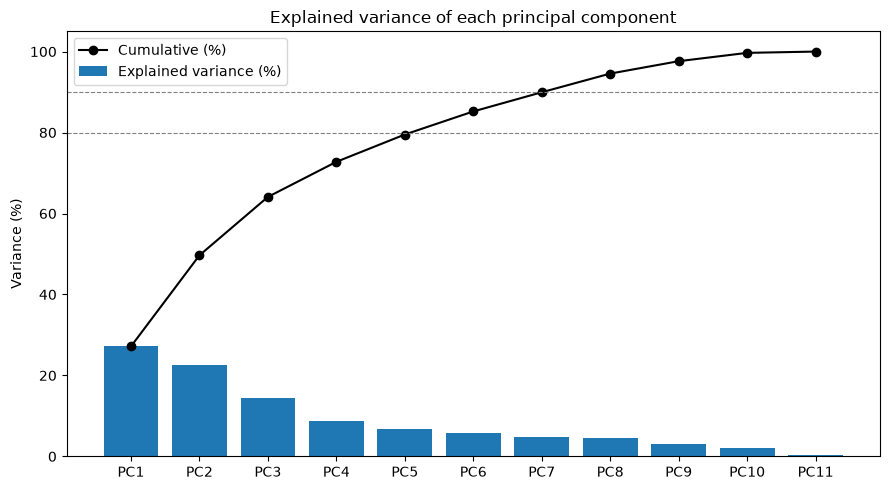

In [350]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(pc_names, expl, label='Explained variance (%)')
ax.plot(pc_names, cum, marker='o', color='black', label='Cumulative (%)')
for t in [80, 90]:
    ax.axhline(t, linestyle='--', linewidth=0.8, color='grey')
ax.set_ylabel('Variance (%)')
ax.set_title('Explained variance of each principal component')
ax.legend()
plt.tight_layout()
plt.savefig('figures/wine_scree.png', dpi=200)
plt.show()

### 3. Number of selected PCs

In [351]:
k_tab = pd.DataFrame({
    'Retained variance (%)': cum,
    'Discarded variance (%)': 100 - cum,
    'Dimensions removed': d - np.arange(1, d + 1),
}, index=pd.Index(range(1, d + 1), name='Number of PCs selected')).round(2)

for t in [80, 90, 95]:
    print(f'Smallest k with >= {t}% variance:', int(np.argmax(cum >= t)) + 1)
k_tab

Smallest k with >= 80% variance: 6
Smallest k with >= 90% variance: 8
Smallest k with >= 95% variance: 9


,Retained variance (%),Discarded variance (%),Dimensions removed
Number of PCs selected,,,
1,27.17,72.83,10
2,49.67,50.33,9
3,64.10,35.90,8
4,72.77,27.23,7
5,79.51,20.49,6
6,85.21,14.79,5
7,89.95,10.05,4
8,94.57,5.43,3
9,97.63,2.37,2


Highest vs lowest explained variance

In [352]:
ks = [1, 2, 3, 5]
pd.DataFrame({
    'k PCs with highest variance (%)': [expl[:k].sum() for k in ks],
    'k PCs with lowest variance (%)':  [expl[-k:].sum() for k in ks],
}, index=pd.Index(ks, name='k')).round(2)

,k PCs with highest variance (%),k PCs with lowest variance (%)
k,,
1,27.17,0.32
2,49.67,2.37
3,64.10,5.43
5,79.51,14.79


Loadings: which features build PC1–PC3 (the sign of a whole PC can flip; compare sizes and relative signs only)

In [353]:
loadings = pd.DataFrame(eigvecs[:, :3], index=features, columns=['PC1', 'PC2', 'PC3']).round(4)
loadings

,PC1,PC2,PC3
fixed acidity,-0.2749,0.3066,-0.4238
volatile acidity,-0.3897,0.0695,0.3119
citric acid,0.1340,0.2194,-0.5772
residual sugar,0.2976,0.3680,0.1728
chlorides,-0.3196,0.2749,0.0087
free sulfur dioxide,0.4258,0.1412,0.1384
total sulfur dioxide,0.4763,0.1622,0.1158
density,-0.1366,0.5651,0.1844
pH,-0.1879,-0.1873,0.4645
sulphates,-0.3176,0.1578,-0.0740


### 4. Projection and 2D visualization

In [354]:
scores = Z @ eigvecs                        # all 11 PC scores
S = np.cov(scores, rowvar=False)
off_diag = S - np.diag(np.diag(S))
print('Max |covariance| between different PCs:', np.abs(off_diag).max())

pc_df = pd.DataFrame(scores[:, :2], columns=['PC1', 'PC2'])
pc_df['type'] = wine['type'].values
pc_df['quality'] = wine['quality'].values

Max |covariance| between different PCs: 8.041863638420386e-16


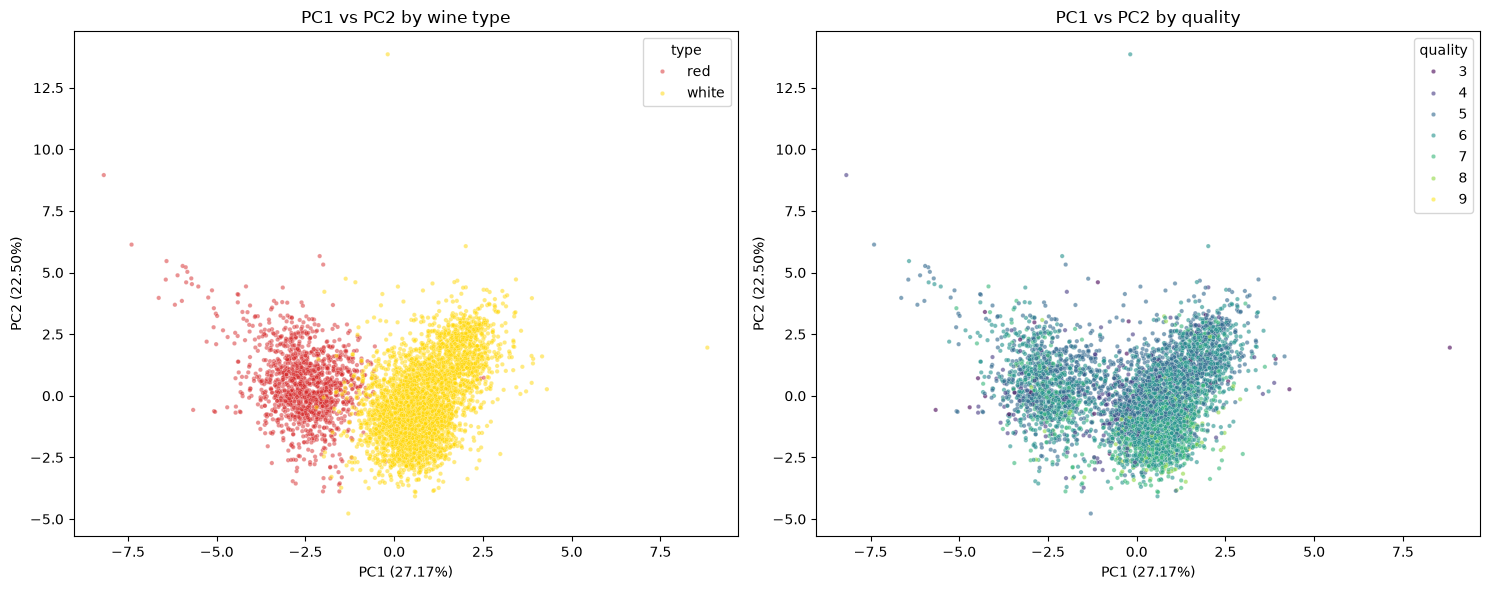

In [355]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=pc_df, x='PC1', y='PC2', hue='type',
                palette={'red': 'tab:red', 'white': 'gold'}, s=10, alpha=0.5, ax=axes[0])
axes[0].set_title('PC1 vs PC2 by wine type')
sns.scatterplot(data=pc_df, x='PC1', y='PC2', hue='quality',
                palette='viridis', s=10, alpha=0.6, ax=axes[1])
axes[1].set_title('PC1 vs PC2 by quality')
for ax in axes:
    ax.set_xlabel(f'PC1 ({expl[0]:.2f}%)')
    ax.set_ylabel(f'PC2 ({expl[1]:.2f}%)')
plt.tight_layout()
plt.savefig('figures/wine_pca_2d.png', dpi=200)
plt.show()

Optional: the two PCs with the lowest explained variance

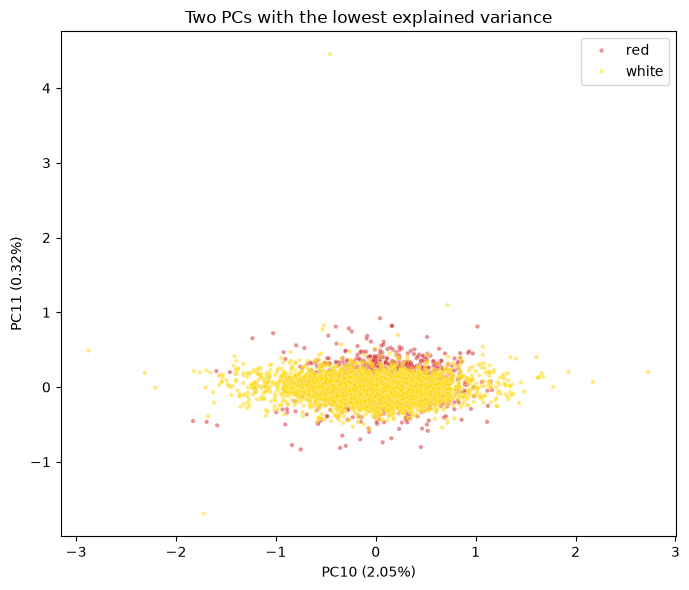

In [356]:
plt.figure(figsize=(7, 6))
sns.scatterplot(x=scores[:, -2], y=scores[:, -1], hue=wine['type'].values,
                palette={'red': 'tab:red', 'white': 'gold'}, s=10, alpha=0.5)
plt.xlabel(f'PC{d-1} ({expl[-2]:.2f}%)')
plt.ylabel(f'PC{d} ({expl[-1]:.2f}%)')
plt.title('Two PCs with the lowest explained variance')
plt.tight_layout()
plt.savefig('figures/wine_pca_lowest.png', dpi=200)
plt.show()

### 5. Sanity check against scikit-learn

In [357]:
try:
    from sklearn.decomposition import PCA
    sk = PCA().fit(Z)
    print('Same explained ratios as by hand:',
          np.allclose(sk.explained_variance_ratio_ * 100, expl))
except ImportError:
    print('scikit-learn not installed: skip this check (pip install scikit-learn)')

Same explained ratios as by hand: True
